# Notebook 06 — De los descriptores a un dataset de ML: tablas de referencia, saneado y primer corte

**Proyecto:** ALCheMy · **Autor:** Ruben Serrano Nieto & AI Agent Pair · **Fecha:** 2026-08-28/29

### Como leer este cuaderno

Este cuaderno no entrena ningun modelo todavia. Documenta la fase F0 del
`methodology/ROADMAP_ML_DESCRIPTORES_QUIMICOS.md`: construir las piezas que
faltaban para tener un dataset de ML honesto (X = condiciones de sintesis +
quimica de metal/linker, Y = `pxrd_labels`), y el saneado de datos que salio
a la luz al construirlas. Cada seccion argumenta una decision con los datos
reales de la base — no es una lista de tareas hecha, es el porque de cada una.

### Indice

1. El marco: dos problemas de ML distintos, y por que solo uno importa
2. Tablas de referencia quimica (F0): metal, ion, linker
3. El cruce automatico metal_source × metal_center: 6 discrepancias reales
4. Un linker sin quimica de coordinacion: por que se borraron 10 sintesis
5. Primer corte del dataset: la consulta, y lo que esconde
6. Dos descriptores que no significan lo que parecen a primera vista
7. Que queda abierto

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psycopg2
import psycopg2.extras
from dotenv import load_dotenv

# Resolucion de ruta robusta: funciona lanzado desde la raiz del repo o desde notebooks/
env_path = '.env' if os.path.exists('.env') else os.path.join('..', '.env')
load_dotenv(env_path)

conn = psycopg2.connect(
    host=os.getenv('POSTGRES_HOST', 'localhost'),
    port=int(os.getenv('POSTGRES_PORT', 5432)),
    dbname=os.getenv('POSTGRES_DB', 'alchemy_db'),
    user=os.getenv('POSTGRES_USER'),
    password=os.getenv('POSTGRES_PASSWORD'),
)

def q(sql, params=None):
    return pd.read_sql(sql, conn, params=params)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)

# Misma paleta que app/pxrd_explorer.py y app/pxrd_labeler.py, para que las
# figuras de este cuaderno se lean como parte del mismo sistema visual.
C_AMOR, C_INC, C_CRYS, C_MEZ = '#e8a33d', '#7e57c2', '#1f7a8c', '#c0392b'
CLASS_COLORS = {'AMORFO': C_AMOR, 'INCIPIENTE': C_INC, 'CRISTALINO': C_CRYS, 'MEZCLA': C_MEZ}
CLASS_ORDER = ['AMORFO', 'INCIPIENTE', 'CRISTALINO', 'MEZCLA']

print('Conectado a', os.getenv('POSTGRES_DB'))

Conectado a alchemy_db


## 1. El marco: dos problemas de ML distintos, y por que solo uno importa

Con `pxrd_descriptors` (1.874 filas) y `pxrd_labels` (etiqueta humana por
medicion) ya cerrados, hay materia prima para DOS modelos de ML muy distintos
que comparten tablas pero no comparten valor:

1. **descriptores del PXRD -> clase.** Predecir la etiqueta a partir de los
   29 numeros que `src/pxrd_descriptors.py` calcula sobre la propia curva.
   Es casi circular: esos descriptores se DISEÑARON para separar las clases
   (ver notebook 05 §7.4). Un acierto alto aqui valida el pipeline de senal,
   no descubre nada sobre la sintesis.
2. **condiciones de sintesis -> clase.** Metal, linker, temperatura, rampa,
   ratio L/M, moduladores -> ¿sale cristalino? Este es el que tiene valor real:
   predice ANTES de meter el reactor en la estufa, con datos que existen antes
   de medir nada.

Este cuaderno prepara la materia prima del problema (2). Dos reglas de higiene
que se siguen desde ya, no al final:

- **La unidad de particion es `sample_code`, no `measurement_id`.** Una misma
  muestra fisica puede tener varias medidas PXRD etiquetadas (ver §5) — si el
  train/test split se hace por fila, la misma muestra cae a los dos lados y
  el modelo parece mejor de lo que es.
- **`metal_center`, `linker`, `hts_number`, `synthesis_date`, `metal_source`
  se guardan en `v_ml_features` solo para AGRUPAR la validacion cruzada
  (`GroupKFold`), nunca como feature de entrada** — son la razon de ser de
  las tablas de la seccion 2: existen precisamente para no tener que meter
  esas columnas categoricas crudas en el modelo.

In [2]:
counts = q('''
    SELECT 'synthesis_experiments' AS tabla, count(*) FROM synthesis_experiments
    UNION ALL SELECT 'characterization_measurements', count(*) FROM characterization_measurements
    UNION ALL SELECT 'pxrd_descriptors', count(*) FROM pxrd_descriptors
    UNION ALL SELECT 'pxrd_labels', count(*) FROM pxrd_labels
    UNION ALL SELECT 'v_ml_features', count(*) FROM v_ml_features
''')
counts

C:\Users\rubbe\AppData\Local\Temp\ipykernel_15060\2132507871.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(sql, conn, params=params)


,tabla,count
0,synthesis_experiments,3204
1,characterization_measurements,3926
2,pxrd_descriptors,1874
3,pxrd_labels,4834
4,v_ml_features,2154


## 2. Tablas de referencia quimica (F0)

### 2.1 Por que un metal no es una etiqueta

`metal_center` tiene 20 valores reales con una distribucion muy desigual
(cientos de Ca/Ni, un puñado de Nd/Dy). One-hot encoding trata `Zr` y `Hf`
—qumicamente casi identicos, misma columna y estado de oxidacion tipico,
radio ionico a 6 pm de diferencia— como si no tuvieran nada en comun. La
tabla `element_properties` sustituye la etiqueta por electronegatividad,
dureza absoluta, radio ionico y (desde esta sesion) oxofilicidad, para que
el modelo pueda compartir fuerza estadistica entre metales parecidos.

In [3]:
elem = q('SELECT * FROM element_properties ORDER BY symbol')
elem[['symbol', 'electronegativity_pauling', 'absolute_hardness_ev',
      'oxophilicity_kepp', 'is_lanthanide']]

C:\Users\rubbe\AppData\Local\Temp\ipykernel_15060\2132507871.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(sql, conn, params=params)


,symbol,electronegativity_pauling,absolute_hardness_ev,oxophilicity_kepp,is_lanthanide
0,Bi,2.02,3.171577,0.2,False
1,Ca,1.00,3.044303,0.3,False
2,Ce,1.12,2.444300,0.9,True
3,Co,1.88,3.609377,0.4,False
4,Cr,1.66,3.050255,0.6,False
5,Cu,1.90,3.245690,0.2,False
6,Dy,1.22,2.793530,0.9,True
7,Fe,1.83,3.875734,0.4,False
8,Ga,1.81,2.784651,NaN,False
9,Hf,1.30,3.405535,1.0,False


### 2.2 El estado de oxidacion sale de la formula del precursor, no del "mas comun"

Si se asignara a cada metal su estado de oxidacion tipico de manual, Fe, Ce y
Ti saldrian mal: este laboratorio usa mas de un estado real de cada uno
(`FeCl3` -> Fe3+ pero `FeCl2` -> Fe2+; `CeCl3` -> Ce3+ pero el nitrato cerico
amonico -> Ce4+). `metal_source_oxidation_state` parsea la formula de cada
precursor a mano (unas ~45 formulas distintas en toda la base), no el metal.

In [4]:
mso = q('''
    SELECT metal_source, symbol, oxidation_state
    FROM metal_source_oxidation_state
    WHERE symbol IN ('Fe', 'Ce') ORDER BY symbol, oxidation_state
''')
mso

C:\Users\rubbe\AppData\Local\Temp\ipykernel_15060\2132507871.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(sql, conn, params=params)


,metal_source,symbol,oxidation_state
0,CeCl3·7H2O,Ce,3
1,Ce(NH4)2(NO3)6,Ce,4
2,FeCl2·4H2O,Fe,2
3,FeCl3.6H2O,Fe,3
4,FeCl3·6H2O,Fe,3


### 2.3 Linkers: 3 esqueletos por 2 estados de proteccion, no 6 categorias sueltas

Los 6 valores de `linker` no son 6 categorias independientes: son 3
esqueletos moleculares (triazina-fosfonato, pireno-fosfonato, polifenol)
cruzados con 2 estados de proteccion (acido libre / ester etilico).
`linker_properties` escribe esa estructura explicitamente via RDKit sobre
SMILES verificados. Disciplina del roadmap §4.4: con solo 6 moleculas, los
200+ descriptores de RDKit darian al modelo mas columnas que objetos
("linker n.3 siempre cristaliza" no es quimica) — por eso solo hay 6
descriptores, elegidos porque cada uno plausiblemente controla el ensamblaje
del MOF (denticidad -> conectividad, distancia donor-donor -> tamaño de
poro, enlaces rotables -> rigidez).

In [5]:
lp = q('SELECT * FROM linker_properties ORDER BY scaffold, protection_state')
lp[['linker_code', 'scaffold', 'protection_state', 'denticity',
    'n_acidic_protons', 'max_donor_distance_a', 'n_rotatable_bonds']]

C:\Users\rubbe\AppData\Local\Temp\ipykernel_15060\2132507871.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(sql, conn, params=params)


,linker_code,scaffold,protection_state,denticity,n_acidic_protons,max_donor_distance_a,n_rotatable_bonds
0,Tannic acid,polyphenol,none,NaN,20,16.38,9.0
1,Pyrene,pyrene_bare,none,0.0,0,NaN,0.0
2,Et8ptp,pyrene_phosphonate,ethyl_ester,0.0,0,9.41,20.0
3,H8ptp,pyrene_phosphonate,free_acid,4.0,8,9.36,4.0
4,Et6ttbmp,triazine_phosphonate,ethyl_ester,0.0,0,14.20,21.0
5,H6ttbmp,triazine_phosphonate,free_acid,3.0,6,14.17,9.0


### 2.4 Oxofilicidad de Kepp (2016): de "no se puede automatizar" a los 19 numeros reales

Al construir F0 la primera vez, la Tabla 1 de Kepp, K. P. *Inorg. Chem.*
**2016**, *55*, 9461-9470 (DOI
[10.1021/acs.inorgchem.6b01702](https://doi.org/10.1021/acs.inorgchem.6b01702))
estaba detras de un muro de pago y no se encontro ninguna reproduccion libre.
Ruben aporto el PDF el 2026-08-29; la tabla completa (69 elementos) se
transcribio a mano. **Gaan no aparece en la Tabla 1 del propio articulo** —
del grupo III el autor solo mide/calcula B, Al e In — asi que
`oxophilicity_kepp` para Ga sigue NULL, no por omision nuestra sino porque la
fuente no lo tiene.

El propio Kepp reporta que la oxofilicidad correlaciona mas con la
electronegatividad que con la dureza (R2 ~ 0,64 para el bloque d). La figura
de abajo lo comprueba sobre los 19 metales que sí tenemos.

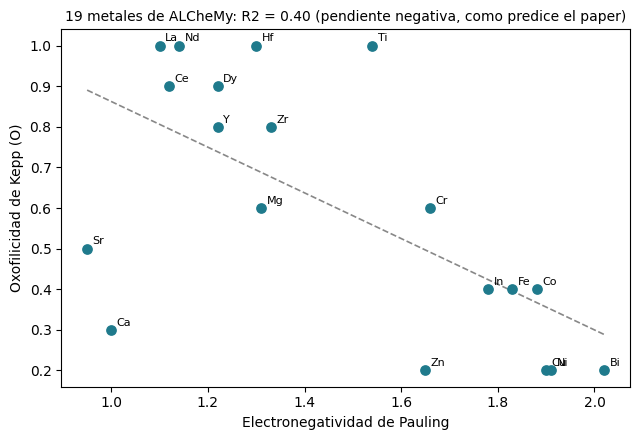

Ga queda NULL: no esta en la Tabla 1 del propio Kepp.


In [6]:
ox = elem.dropna(subset=['oxophilicity_kepp', 'electronegativity_pauling'])
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(ox['electronegativity_pauling'], ox['oxophilicity_kepp'], color=C_CRYS, s=45, zorder=3)
for _, r in ox.iterrows():
    ax.annotate(r['symbol'], (r['electronegativity_pauling'], r['oxophilicity_kepp']),
                fontsize=8, xytext=(4, 3), textcoords='offset points')
m, b = np.polyfit(ox['electronegativity_pauling'], ox['oxophilicity_kepp'], 1)
xs = np.linspace(ox['electronegativity_pauling'].min(), ox['electronegativity_pauling'].max(), 20)
ax.plot(xs, m * xs + b, ls='--', color='#888', lw=1.2, zorder=1)
r2 = np.corrcoef(ox['electronegativity_pauling'], ox['oxophilicity_kepp'])[0, 1] ** 2
ax.set_xlabel('Electronegatividad de Pauling')
ax.set_ylabel('Oxofilicidad de Kepp (O)')
ax.set_title('19 metales de ALCheMy: R2 = %.2f (pendiente negativa, como predice el paper)' % r2, fontsize=10)
fig.tight_layout()
plt.show()
print('Ga queda NULL: no esta en la Tabla 1 del propio Kepp.')

### 2.5 Radios de Shannon: dos excepciones documentadas, no dudosas

`pymatgen` trae la tabla de radios ionicos de Shannon (1976), pero para dos
pares (elemento, carga) que este laboratorio necesita —Cr3+ y Ni2+— solo
tenia tabulado el otro estado de oxidacion (Cr2+, Ni3+). Los dos valores que
faltan (61,5 pm y 69,0 pm respectivamente) se rellenaron a mano con el CRC
Handbook, no con nada del articulo de Kepp — son manual estandar de quimica
inorganica, con cita en el codigo.

## 3. El cruce automatico metal_source × metal_center: 6 discrepancias reales

`src/build_element_properties.py` compara, para cada `metal_source` distinto,
el conjunto de `metal_center` con los que aparece. Si un mismo precursor
aparece bajo mas de un metal, es un error de transcripcion en alguna de las
dos columnas — nunca adivinado, siempre marcado
`matches_metal_center = FALSE` hasta que un humano lo revisa
(`methodology/PENDIENTE_ML_INPUTS_HUMANOS.md`). La primera pasada encontro
6 casos:

| Filas | Se detecto por | Resolucion (2026-08-29) |
|---|---|---|
| RS352-355, RS377-380 (8) | `metal_center=Mg` con precursor de niquel | `metal_source` corregido a `Mg(NO3)2·6H2O`, confirmado contra presentaciones |
| RS1845-1848 (4) | `metal_center=Ti` con `HfCl4` | `metal_center` corregido a `Hf`, por la cantidad de precursor usada |
| RS253 (1) | `metal_center=Bi` con precursor de magnesio | **Resuelto por calculo**, ver abajo — no por memoria |
| RS1939 (1) | indio con estado +2 en la formula | Aceptado como In3+ (el "2" es transcripcion; In(II) no es un estado real en disolucion) |
| RS94, RS95 (2) | sin metal en absoluto | Confirmados como blancos organicos — no es un hueco, es una etiqueta correcta |

RS253 es el unico interesante desde el punto de vista de metodo: Ruben
confirmo que el metal es Bi "con total seguridad" pero no recordaba la sal
exacta. En vez de adivinar entre las 3 sales de Bi que ya existen en la base,
se comparo la masa de precursor YA REGISTRADA contra las tres.

In [7]:
rs253 = q("SELECT sample_code, metal_center, metal_source, metal_conc_m, "
          "total_volume_ml, metal_mass_mg FROM synthesis_experiments WHERE sample_code='RS253'")
mmol = float(rs253['metal_conc_m'].iloc[0]) * float(rs253['total_volume_ml'].iloc[0])  # M * mL = mmol

salts = {
    'Bi(NO3)3.5H2O': 485.06,   # 208.98 + 3*62.00 + 5*18.015 -- forma en DB: Bi(NO3)3·5H2O
    'BiCl3':          315.34,
    'BiClO':          260.43,
}
comp = pd.DataFrame({
    'sal': list(salts.keys()),
    'MW (g/mol)': list(salts.values()),
    'masa esperada (mg)': [mmol * mw for mw in salts.values()],
})
comp['|diferencia| vs registrado (mg)'] = (comp['masa esperada (mg)'] - float(rs253['metal_mass_mg'].iloc[0])).abs()
print('Masa registrada en RS253: %.4f mg (a %.4f M, %.2f mL -> %.4f mmol)'
      % (rs253['metal_mass_mg'].iloc[0], rs253['metal_conc_m'].iloc[0],
         rs253['total_volume_ml'].iloc[0], mmol))
comp.sort_values('|diferencia| vs registrado (mg)')

Masa registrada en RS253: 2.1828 mg (a 0.0030 M, 1.50 mL -> 0.0045 mmol)


C:\Users\rubbe\AppData\Local\Temp\ipykernel_15060\2132507871.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(sql, conn, params=params)


,sal,MW (g/mol),masa esperada (mg),|diferencia| vs registrado (mg)
0,Bi(NO3)3.5H2O,485.06,2.182770,0.000030
1,BiCl3,315.34,1.419030,0.763770
2,BiClO,260.43,1.171935,1.010865


`Bi(NO3)3·5H2O` es la unica que coincide (diferencia < 0,001 mg; las
otras dos difieren en mas de medio miligramo, un 25-40% — no es ambiguo).
`metal_source` de RS253 se corrigio a `Bi(NO3)3·5H2O`. Verificacion: tras
esta correccion, el cruce automatico da **0 discrepancias**.

In [8]:
mismatches = q('''
    SELECT count(*) AS n_mismatches
    FROM metal_source_oxidation_state
    WHERE matches_metal_center = FALSE
''')
mismatches

C:\Users\rubbe\AppData\Local\Temp\ipykernel_15060\2132507871.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(sql, conn, params=params)


,n_mismatches
0,0


## 4. Un linker sin quimica de coordinacion: por que se borraron 10 sintesis

`linker = 'Pyrene'` es pireno desnudo — sin grupos fosfonato, sin ningun
atomo donor que pueda coordinar un metal. No puede formar un MOF por
definicion quimica, asi que las 10 sintesis que lo usaban (`UNKNOWN`, `IEF-8`,
`IEF-18`, `IEF-31`, las 4 de la serie `IEF-22`, `RSMIX10`, `RSMIX15`) no
representan una via de sintesis real para el problema que se quiere modelar
— son las que motivaron el hueco de `reactor_volume_ml` de la sesion
anterior, y la razon (confirmada por Ruben) es que nunca deberian haber
llegado tan lejos en el pipeline.

Se borraron de `synthesis_experiments`, confirmado explicitamente por Ruben
tras enseñarle el recuento real (eran 10, no las "2" que recordaba de
memoria — la diferencia importaba antes de borrar nada). El CASCADE de la
FK se llevo 152 filas de `characterization_measurements` y 2 de
`pxrd_descriptors`. Al hacerlo goteo un hueco de esquema real:
`pxrd_labels.measurement_id` no tiene clave foranea (a diferencia de
`pxrd_descriptors`, que si la tiene), asi que 13 etiquetas humanas se
quedaron huerfanas — apuntando a medidas ya borradas. Se limpiaron a mano,
confirmado con Ruben. **Queda pendiente anadir esa FK** para que el proximo
borrado no repita el mismo hueco.

In [9]:
orphans = q('''
    SELECT count(*) AS pyrene_restante
    FROM synthesis_experiments WHERE linker = 'Pyrene'
''')
orphan_labels = q('''
    SELECT count(*) AS labels_huerfanas
    FROM pxrd_labels pl
    LEFT JOIN characterization_measurements cm ON cm.measurement_id = pl.measurement_id
    WHERE cm.measurement_id IS NULL
''')
pd.concat([orphans, orphan_labels], axis=1)

C:\Users\rubbe\AppData\Local\Temp\ipykernel_15060\2132507871.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(sql, conn, params=params)


,pyrene_restante,labels_huerfanas
0,0,0


## 5. Primer corte del dataset: la consulta, y lo que esconde

La consulta de arranque, tal y como se propuso, es el join directo:

```sql
SELECT v.*, l.label_value
  FROM v_ml_features v
  JOIN pxrd_labels l USING (sample_code)
 WHERE l.label_type = 'crystallinity_class'
   AND l.label_value <> 'SIN_MUESTRA';
```

Contar FILAS de ese join da una cosa; contar `sample_code` DISTINTOS da otra
mas pequeña. La diferencia es el primer problema de higiene real del
dataset: hay muestras con mas de una medida PXRD, cada una etiquetada por
separado.

In [10]:
join_df = q('''
    SELECT l.measurement_id, cm.sample_code, l.label_value AS clase
    FROM pxrd_labels l
    JOIN characterization_measurements cm ON cm.measurement_id = l.measurement_id
    JOIN synthesis_experiments s ON s.sample_code = cm.sample_code
    WHERE l.label_type = 'crystallinity_class' AND l.label_value <> 'SIN_MUESTRA'
      AND s.synthesis_type NOT IN ('REFERENCE', 'PENDING_RECORD')
''')
print('Filas (una por medida etiquetada):', len(join_df))
print('sample_code distintos:           ', join_df['sample_code'].nunique())

dup = join_df.groupby('sample_code').size()
dup = dup[dup > 1].sort_values(ascending=False)
print('Muestras con mas de una medida etiquetada:', len(dup))
dup.head(10).rename('n_medidas').to_frame()

Filas (una por medida etiquetada): 1838
sample_code distintos:            1793
Muestras con mas de una medida etiquetada: 43


C:\Users\rubbe\AppData\Local\Temp\ipykernel_15060\2132507871.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(sql, conn, params=params)


,n_medidas
sample_code,
RS1915,4
LP126,2
LP125,2
LP97,2
RS1012,2
RS1452,2
RS1453,2
RS1454,2
RS1455,2


Estas ~24 muestras estan puestas como un filtro puntual en
`app/pxrd_explorer.py` ("0 · Revision puntual para ML" -> "Muestras con mas
de una etiqueta") para que Ruben decida, viendo las curvas, si son
repeticiones concordantes (quedarse con una, cualquiera) o si alguna es un
caso donde la muestra cambio entre medidas (quedarse con la mas reciente,
o tratarlas como observaciones separadas del mismo `sample_code` en el
`GroupKFold`). **Pendiente su veredicto**, ver §7.

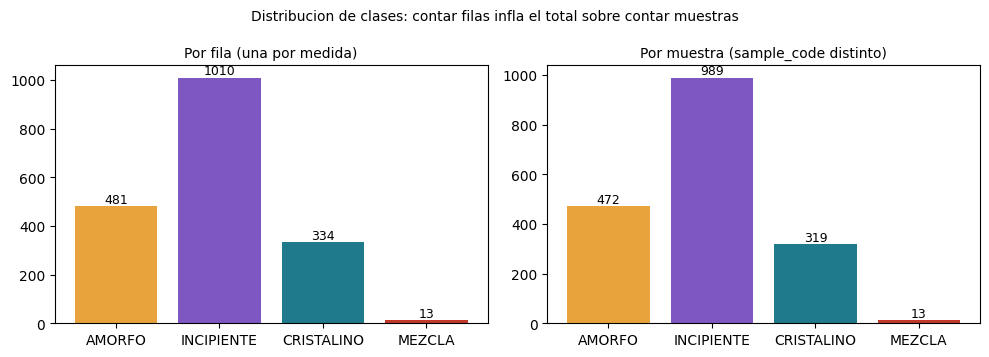

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (title, series) in zip(axes, [
    ('Por fila (una por medida)', join_df['clase'].value_counts()),
    ('Por muestra (sample_code distinto)', join_df.drop_duplicates('sample_code')['clase'].value_counts()),
]):
    order = [c for c in CLASS_ORDER if c in series.index]
    ax.bar(order, [series[c] for c in order], color=[CLASS_COLORS[c] for c in order])
    ax.set_title(title, fontsize=10)
    for i, c in enumerate(order):
        ax.text(i, series[c], str(series[c]), ha='center', va='bottom', fontsize=9)
fig.suptitle('Distribucion de clases: contar filas infla el total sobre contar muestras', fontsize=10)
fig.tight_layout()
plt.show()

**MEZCLA** son 13 muestras distintas (16 medidas) — el 0,7% del total.
Con tan pocos casos no se puede aprender la clase como una cuarta categoria
independiente; Ruben va a revisarlas en `pxrd_explorer` (filtro "MEZCLA") para
decidir si se fusionan con AMORFO o se excluyen del modelo. **Pendiente.**

In [12]:
oxide_amorfo = q('''
    SELECT count(DISTINCT cm.sample_code) AS muestras, count(*) AS medidas
    FROM pxrd_labels lc
    JOIN pxrd_labels lo ON lo.measurement_id = lc.measurement_id AND lo.label_type = 'oxide_flag'
    JOIN characterization_measurements cm ON cm.measurement_id = lc.measurement_id
    WHERE lc.label_type = 'crystallinity_class' AND lc.label_value = 'AMORFO' AND lo.label_value = 'SI'
''')
oxide_amorfo

C:\Users\rubbe\AppData\Local\Temp\ipykernel_15060\2132507871.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(sql, conn, params=params)


,muestras,medidas
0,70,70


**70 medidas etiquetadas AMORFO tienen `oxide_flag = 'SI'`** — Ruben
recordo, al discutir por que `crystallinity_reliable` rechaza casi toda la
clase AMORFO, que ya habia anotado en su momento cuando una muestra "amorfa"
mostraba picos claros de un oxido. Estan puestas como filtro puntual en
`pxrd_explorer` ("AMORFO marcado como oxido") para que decida, caso a caso:
si de verdad es oxido cristalino, la muestra se descarta del dataset o se
reclasifica — es una decision de quimica, no de estadistica. **Pendiente.**

## 6. Dos descriptores que no significan lo que parecen a primera vista

### `amorphous_fraction_blank`: el suelo esta abajo, no arriba

No es "cuanto amorfo hay en total": es la fraccion de lo que la MUESTRA
dispersó (descontando el instrumento) que fue difuso en vez de picos de
Bragg. Sale alto en AMORFO como deberia — el problema esta en el otro
extremo.

C:\Users\rubbe\AppData\Local\Temp\ipykernel_15060\2132507871.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(sql, conn, params=params)


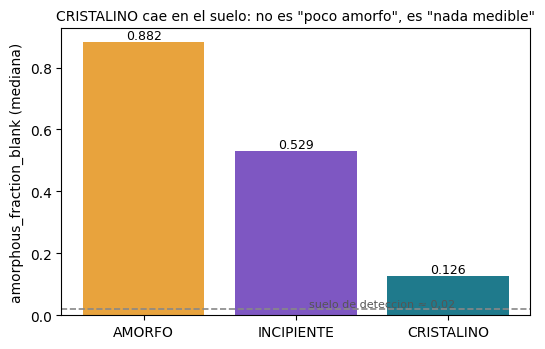

In [13]:
frac = q('''
    SELECT lc.label_value AS clase, pd.amorphous_fraction_blank
    FROM pxrd_labels lc
    JOIN pxrd_descriptors pd ON pd.measurement_id = lc.measurement_id
    WHERE lc.label_type = 'crystallinity_class'
      AND lc.label_value IN ('AMORFO', 'INCIPIENTE', 'CRISTALINO')
      AND pd.amorphous_fraction_blank IS NOT NULL
''')
med = frac.groupby('clase')['amorphous_fraction_blank'].median().reindex(['AMORFO', 'INCIPIENTE', 'CRISTALINO'])
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.bar(med.index, med.values, color=[CLASS_COLORS[c] for c in med.index])
ax.axhline(0.02, color='#888', ls='--', lw=1.2)
ax.text(2.05, 0.02, 'suelo de deteccion ≈ 0,02', va='bottom', ha='right', fontsize=8, color='#555')
for i, c in enumerate(med.index):
    ax.text(i, med[c], '%.3f' % med[c], ha='center', va='bottom', fontsize=9)
ax.set_ylabel('amorphous_fraction_blank (mediana)')
ax.set_title('CRISTALINO cae en el suelo: no es "poco amorfo", es "nada medible"', fontsize=10)
fig.tight_layout()
plt.show()

CRISTALINO da ~0,01 — por debajo del suelo de deteccion del metodo
(~0,02, ver notebook 05 §7.5). **No hay que leer ese numero como "1% de fase
amorfa real"**: es ruido residual de la linea base, no señal. Para el
dataset de ML, cualquier valor por debajo del suelo deberia tratarse como
"amorfo no detectable" (posiblemente binarizando por debajo del umbral) en
vez de como una cantidad continua con significado fisico ahi abajo.

### `crystallinity_reliable`: mide señal total, no "si es cristalino"

Es un umbral sobre `signal_snr_area` — la intensidad total dispersada
(difusa + picos, cualquiera de las dos) frente al ruido de contaje. Una
muestra genuinamente amorfa con señal debil (poco material, halo tenue) lo
falla igual que una medida basura, aunque la clasificacion sea correcta.

C:\Users\rubbe\AppData\Local\Temp\ipykernel_15060\2132507871.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(sql, conn, params=params)


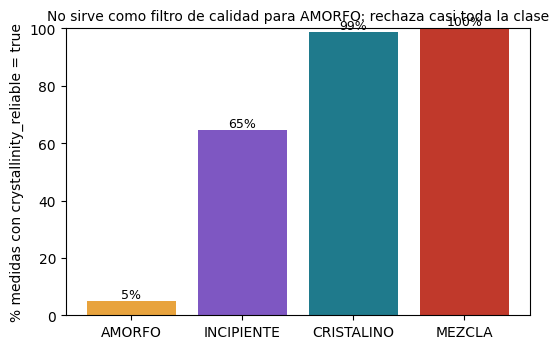

In [14]:
rel = q('''
    SELECT lc.label_value AS clase, pd.crystallinity_reliable
    FROM pxrd_labels lc
    JOIN pxrd_descriptors pd ON pd.measurement_id = lc.measurement_id
    WHERE lc.label_type = 'crystallinity_class'
      AND lc.label_value IN ('AMORFO', 'INCIPIENTE', 'CRISTALINO', 'MEZCLA')
''')
pct = rel.groupby('clase')['crystallinity_reliable'].mean().reindex(CLASS_ORDER).dropna() * 100
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.bar(pct.index, pct.values, color=[CLASS_COLORS[c] for c in pct.index])
for i, c in enumerate(pct.index):
    ax.text(i, pct[c], '%.0f%%' % pct[c], ha='center', va='bottom', fontsize=9)
ax.set_ylabel('% medidas con crystallinity_reliable = true')
ax.set_ylim(0, 100)
ax.set_title('No sirve como filtro de calidad para AMORFO: rechaza casi toda la clase', fontsize=10)
fig.tight_layout()
plt.show()

Conclusion practica para el dataset de ML: **no usar
`crystallinity_reliable` para descartar filas de AMORFO** — dejaria la clase
casi vacia. Puede quedarse como una feature/flag mas, pero no como filtro
de inclusion.

## 7. Que queda abierto

Nada de esto bloquea seguir, pero condiciona como se construye el dataset
final. Pendiente de veredicto humano, revisando en `app/pxrd_explorer.py`
(filtro "0 · Revision puntual para ML"):

1. **~24 muestras con mas de una medida etiquetada** (§5) — que medicion se
   queda, o si se agrupan como repeticiones.
2. **13 muestras MEZCLA** (§5) — fusionar con AMORFO, o excluir del modelo.
3. **70 medidas AMORFO con `oxide_flag='SI'`** (§5) — cuales son oxido de
   verdad y se descartan/reclasifican.

Y una decision de ingenieria de features, no de quimica:

4. Tratar `amorphous_fraction_blank` por debajo de ~0,02 como "no detectable"
   en vez de una cantidad continua (§6), y no usar `crystallinity_reliable`
   como filtro de inclusion para AMORFO (§6).

**Esquema:** `pxrd_labels.measurement_id` deberia llevar
`REFERENCES characterization_measurements(measurement_id) ON DELETE CASCADE`
para que un borrado futuro no vuelva a dejar etiquetas huerfanas (§4).

Con esas 4 respuestas, el siguiente paso es construir el dataset final
agrupado por `sample_code` y entrenar el primer modelo base (LightGBM
multiclase, `GroupKFold` por `sample_code`) para el problema que de verdad
importa: condiciones de sintesis -> clase de cristalinidad.

In [15]:
conn.close()
print('Conexion cerrada. Este cuaderno no escribe nada en la base de datos.')

Conexion cerrada. Este cuaderno no escribe nada en la base de datos.
